In [1]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom

import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)

import pyvista as pv

def remove_zeros(array):
    a = onp.array(array)
    a[onp.abs(a) < 1e-14] = 0.0
    return a

from jax_sn.domain.geometric_domain import GeometricDomain, TopologicalSortedAngle
from jax_sn.solution_domain.solution_domain import FEMMatrices, PrecomputedGeometricData
from jax_sn.domain.geometric_domain import CrossSectionData, CrossSectionDataSingleGroup
from jax_sn.source import Source
from jax_sn.operators.transport_operator import TransportOperatorBatched, TransportOperatorMultipleAnglesVmap, TransportOperatorVmap, TransportOperatorBatchedPallas
from jax_sn.operators.mass_operator import MassOperator
from jax_sn.operators.moment_operator import MomentOperator

from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
import matplotlib.pyplot as plt
from dataclasses import dataclass
onp.set_printoptions(linewidth = 200)
from finite_elements.test_moment_scatter_operator import _setup_all_sb

In [2]:
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex
from jax_sn.solution_domain import SolutionDomain
from jax_sn.domain import CrossSectionData, Domain
from jax_sn.source import Source

In [30]:
from finite_elements.test_anisotropic_scattering import _setup_anisotropic_scattering_args
dim = 2
degree = 2
n_elem_regions = [6, 3, 10, 6, 3, 3, 3]

d_other_dim = 5.0
n_other_dim = 3
tn_order = 3
args_ani = (dim, degree, n_elem_regions, d_other_dim, n_other_dim, tn_order)

Aop, source_total, solution_domain = _setup_anisotropic_scattering_args(dim, degree, n_elem_regions, d_other_dim, n_other_dim, tn_order)

Aop.transport_operator.solution_domain_data.domain.n_elements

204

In [31]:
from jax_sn.tools.memory_analysis import OperatorAnalysis
from jax_sn.operators.single_group_operator import SingleGroupOperator

In [32]:
batched_top = TransportOperatorMultipleAnglesVmap(TransportOperatorBatched(Aop.transport_operator.solution_domain_data, Aop.transport_operator.topological_sorted_angle, 0, batch_size=100))

In [33]:
Aop_new = SingleGroupOperator(Aop.moment_operator, batched_top, Aop.mass_operator, Aop.scatter_operator)

In [34]:
print("Transport operator inv:")
print("\t", OperatorAnalysis.analyze_memory(batched_top,"inv"))
print("Mass operator:")
print("\t", OperatorAnalysis.analyze_memory(Aop.mass_operator,"mv"))
print("Moment operator:")
print("\t", OperatorAnalysis.analyze_memory(Aop.moment_operator, "mv"))
print("Scatter operator:")
print("\t", OperatorAnalysis.analyze_memory(Aop.scatter_operator,"mv"))
print("Total A operator")
print("\t", OperatorAnalysis.analyze_memory(Aop_new, "mv"))

Transport operator inv:
	 {'peak': 9.7777099609375, 'argument': 0.9604034423828125, 'output': 0.6723861694335938, 'temp': 8.149055480957031}
Mass operator:
	 {'peak': 2.69158935546875, 'argument': 0.6741943359375, 'output': 0.6723861694335938, 'temp': 1.345703125}
Moment operator:
	 {'peak': 1.386505126953125, 'argument': 0.674560546875, 'output': 0.03737640380859375, 'temp': 0.675048828125}
Scatter operator:
	 {'peak': 0.7908477783203125, 'argument': 0.041534423828125, 'output': 0.6723861694335938, 'temp': 0.077392578125}
Total A operator
	 {'peak': 9.850753784179688, 'argument': 0.3336029052734375, 'output': 0.03737640380859375, 'temp': 9.484504699707031}


In [35]:
rhs = Aop_new.moment_operator.mv(Aop_new.transport_operator.inv(Aop_new.mass_operator.mv(source_total)))

In [37]:
import lineax as lx

bicgstab_solver = lx.BiCGStab(1e-10, 1e-10, max_steps = 20)

In [38]:
import equinox as eqx

@eqx.filter_jit
def solve_bicgstab(Aop, rhs):
    bicgstab_solver = lx.BiCGStab(1e-10, 1e-10, max_steps = 20)
    solution = lx.linear_solve(Aop, rhs, bicgstab_solver)
    return solution.value


from jax_sn.tools.memory_analysis import _filter_jit_f_to_memory


_filter_jit_f_to_memory(solve_bicgstab, Aop_new, rhs)

{'peak': 10.71450138092041,
 'argument': 0.3593902587890625,
 'output': 0.03737640380859375,
 'temp': 10.341796875}

In [39]:
gmres_solver = lx.GMRES(1e-10, 1e-10)

In [40]:
_filter_jit_f_to_memory(lx.linear_solve, Aop_new, rhs, gmres_solver)

{'peak': 11.039236068725586,
 'argument': 0.3593902587890625,
 'output': 0.3597297668457031,
 'temp': 10.333084106445312}

In [41]:
solution = lx.linear_solve(Aop_new, rhs, bicgstab_solver)

In [42]:
Aop.transport_operator.solution_domain_data.domain.cross_sections_indexed.cross_section_data.total[0,0]

Array(15.209, dtype=float64)

In [ ]:
solution = lx.linear_solve(Aop_new, rhs, bicgstab_solver) #.value = [l, n_elem, n_basis]

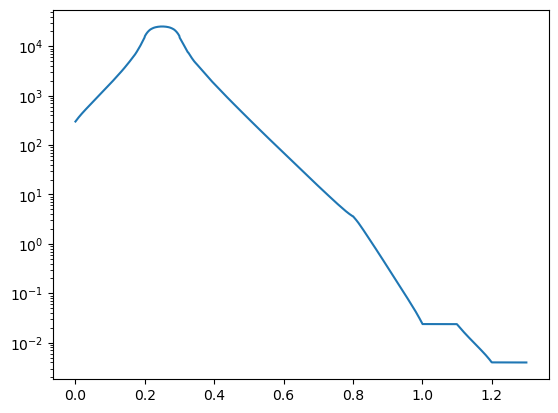

In [57]:
x= jnp.linspace(0,1.3, 1000)
y = jnp.full_like(x, 0.5 * d_other_dim)
xy = jnp.stack([x,y], axis=-1)
phi = solution_domain.interpolate(xy, solution.value[0])
plt.semilogy(x, phi)

In [59]:
def parametrise_A(theta, Aop, rhs):
    return eqx.tree_at(lambda Aop : Aop.transport_operator.solution_domain_data.domain.cross_sections_indexed.cross_section_data.total, Aop, replace_fn = lambda total : total.at[0,0].set(theta))


@eqx.filter_jit
def solve_and_sum(theta, Aop, rhs):
    Aop_param = parametrise_A(theta, Aop, rhs)
    bicgstab_solver = lx.BiCGStab(1e-10, 1e-10, max_steps = 20)
    solution = lx.linear_solve(Aop_param, rhs, bicgstab_solver)
    return jnp.sum(solution.value)



In [60]:
_filter_jit_f_to_memory(lx.linear_solve, Aop_new, rhs, bicgstab_solver)

{'peak': 11.001850128173828,
 'argument': 0.3593902587890625,
 'output': 0.3597297668457031,
 'temp': 10.298171997070312}

In [62]:
_filter_jit_f_to_memory(solve_and_sum, 15.209, Aop_new, rhs)

{'peak': 10.714608192443848,
 'argument': 0.3593902587890625,
 'output': 3.0517578125e-05,
 'temp': 10.379150390625}

In [26]:
f_solve_and_sum_grad = eqx.filter_jit(jax.grad(solve_and_sum, argnums=0)(15.209, Aop_new, rhs))

NotImplementedError: Transpose of SingleGroupOperatorImp is not YET implemented.

In [ ]:

solve_and_sum(15.209, Aop_new, rhs)

In [ ]:
x = jnp.linspace(0, 1.3, 1000)
y = jnp.full_like(x, d_other_dim * 0.5 )
z = jnp.full_like(x, d_other_dim * 0.5 )
xyz = jnp.stack([x, y, z], axis=-1)

interps = solution_domain.interpolate(xyz, solution.value[0])

In [ ]:
from finite_elements.test_anisotropic_scattering import _get_expected_values_sb

In [ ]:
sb_values = _get_expected_values_sb(*args_ani)

In [ ]:
plt.semilogy(x, interps) 

plt.semilogy(x, sb_values, '--')

In [ ]:
print("Transport operator inv:")
print("\t", OperatorAnalysis.analyze_timing(batched_top,"inv", n_samples = 10, ignore_n=2))
print("Mass operator:")
print("\t", OperatorAnalysis.analyze_timing(Aop.mass_operator,"mv", n_samples = 10, ignore_n=2))
print("Moment operator:")
print("\t", OperatorAnalysis.analyze_timing(Aop.moment_operator, "mv", n_samples = 10, ignore_n=2))
print("Scatter operator:")
print("\t", OperatorAnalysis.analyze_timing(Aop.scatter_operator,"mv", n_samples = 10, ignore_n=2))
print("Total A operator")
print("\t", OperatorAnalysis.analyze_timing(Aop_new, "mv", n_samples = 10, ignore_n=2))